# 02 – Nội dung 3: Xây dựng & đánh giá mô hình

Phân khúc khách hàng RFM (K-Means) và mô hình dự đoán rời bỏ có giải thích SHAP.

- **Phần I – Phân khúc khách hàng RFM bằng K-Means:** Công việc 3.3: chọn số cụm, gán nhãn phân khúc, so sánh với phiên bản lỗi.
- **Phần II – Mô hình dự đoán rời bỏ & giải thích SHAP:** Công việc 3.1–3.6: so sánh mô hình, đánh giá out-of-time, chọn ngưỡng, giải thích bằng SHAP.

> **Quyền riêng tư:** dữ liệu đã được ẩn danh hóa bởi `omni_dss/ml/data_cleaning.py`: `customer_id` là mã giả danh (`KH_` + HMAC, không suy ngược được nếu không có khóa), không còn cột số điện thoại hay họ tên. Notebook chỉ hiển thị số liệu tổng hợp.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
from omni_dss.ml import feature_engineering as fe
from omni_dss.ml.dss import mask_customer_id  # che mã dạng số điện thoại khi hiển thị

## Phần I – Phân khúc khách hàng RFM bằng K-Means

### 1. Dữ liệu RFM
F = **số đơn mua thành công**, M = tổng giá trị đơn thành công; F và M lấy log(1 + x) rồi chuẩn hóa z-score.

In [2]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

rfm = fe.read_csv("customer_rfm_features.csv")
X = fe.rfm_feature_frame(rfm["recency_days"], rfm["completed_orders"], rfm["monetary_total"])
Xs = StandardScaler().fit_transform(X)
rfm[["recency_days", "completed_orders", "monetary_total"]].describe().round(1)

,recency_days,completed_orders,monetary_total
count,19100.0,19100.0,19100.0
mean,15.7,0.8,270472.1
std,10.3,0.5,216585.7
min,1.0,0.0,0.0
25%,7.0,1.0,150000.0
50%,14.0,1.0,300000.0
75%,24.0,1.0,380000.0
max,153.0,6.0,4688000.0


### 2. Chọn K: Elbow và Silhouette

,SSE,Silhouette
K,,
2,20802.017,0.688
3,12490.196,0.595
4,6373.408,0.636
5,4674.889,0.665
6,3590.470,0.616
7,3070.901,0.603
8,2543.093,0.569


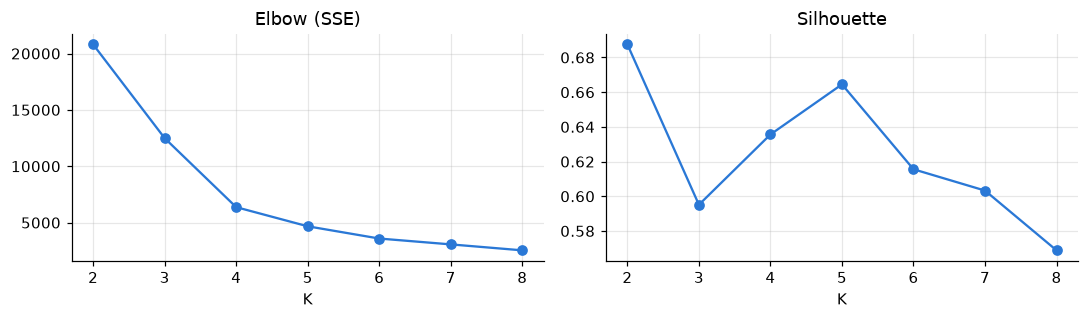

In [3]:
rng = np.random.RandomState(42); sample = rng.choice(len(Xs), 5000, replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(k, random_state=42, n_init=10).fit(Xs)
    rows.append({"K": k, "SSE": km.inertia_, "Silhouette": silhouette_score(Xs[sample], km.labels_[sample])})
sel = pd.DataFrame(rows).set_index("K")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sel["SSE"].plot(ax=axes[0], marker="o", color=C[0], title="Elbow (SSE)")
sel["Silhouette"].plot(ax=axes[1], marker="o", color=C[0], title="Silhouette")
plt.tight_layout()
sel.round(3)

K = 2 chỉ tách *đã mua / chưa mua*. Trong K ∈ [4, 8] (đủ 4 phân khúc nghiệp vụ), chọn Silhouette cao nhất.

In [4]:
k_best = sel.loc[4:].Silhouette.idxmax(); print("K được chọn:", k_best)
km = KMeans(k_best, random_state=42, n_init=10).fit(Xs)
seg_map = fe.rank_rfm_centroids(km.cluster_centers_)
rfm["cluster"], rfm["segment"] = km.labels_, pd.Series(km.labels_).map(seg_map).values
prof = rfm.groupby(["segment", "cluster"]).agg(so_khach=("cluster", "size"), R_tb=("recency_days", "mean"),
                                                F_tb=("completed_orders", "mean"), ty_le_mua_lai=("completed_orders", lambda s: (s >= 2).mean()),
                                                M_trung_vi=("monetary_total", "median"))
prof["ty_trong"] = prof["so_khach"] / len(rfm)
prof.round(3)

K được chọn: 5


so_khach    R_tb   F_tb  ty_le_mua_lai  M_trung_vi  \
segment      cluster                                                       
Cần chăm sóc 2            6295  25.386  1.006          0.006    300000.0   
Rủi ro       1            2904   4.339  0.000          0.000         0.0   
             4            1314  31.289  0.000          0.000         0.0   
Tiềm năng    0            7542   9.851  1.000          0.000    300000.0   
VIP          3            1045  12.307  2.141          1.000    626000.0   

                      ty_trong  
segment      cluster            
Cần chăm sóc 2           0.330  
Rủi ro       1           0.152  
             4           0.069  
Tiềm năng    0           0.395  
VIP          3           0.055

### 3. So sánh với phiên bản lỗi (F = tổng số đơn, K = 4)
Phiên bản đầu tính F bằng **tổng số đơn** (gồm cả đơn hủy/hoàn). Cụm "VIP" khi đó là mọi khách có ≥ 2 đơn, kể cả khách không có đơn thành công nào.

In [5]:
X_old = StandardScaler().fit_transform(fe.rfm_feature_frame(rfm["recency_days"], rfm["total_orders"], rfm["monetary_total"]))
km_old = KMeans(4, random_state=42, n_init=10).fit(X_old)
old_seg = pd.Series(km_old.labels_).map(fe.rank_rfm_centroids(km_old.cluster_centers_)).values
vip_old = rfm[old_seg == "VIP"]; vip_new = rfm[rfm["segment"] == "VIP"]
pd.DataFrame({
    "Số khách VIP": [len(vip_old), len(vip_new)],
    "VIP có 0 đơn thành công": [int((vip_old["completed_orders"] == 0).sum()), int((vip_new["completed_orders"] == 0).sum())],
    "% VIP mua thành công >= 2 lần": [(vip_old["completed_orders"] >= 2).mean(), (vip_new["completed_orders"] >= 2).mean()],
}, index=["Cũ: F = tổng đơn, K=4", f"Mới: F = đơn thành công, K={k_best}"]).round(3)

,Số khách VIP,VIP có 0 đơn thành công,% VIP mua thành công >= 2 lần
"Cũ: F = tổng đơn, K=4",1791,141,0.604
"Mới: F = đơn thành công, K=5",1045,0,1.000


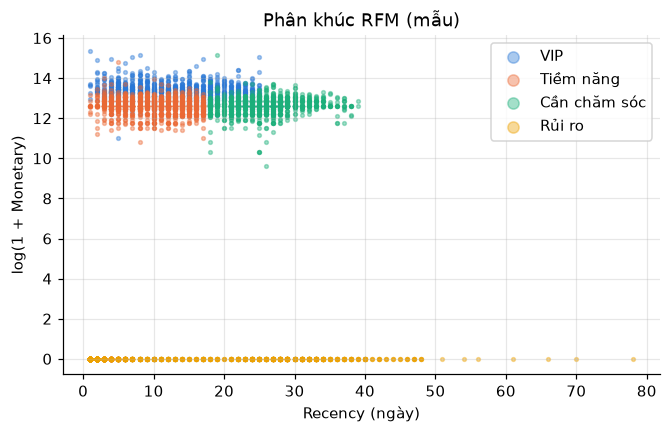

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, s in enumerate(fe.SEGMENT_LABELS):
    d = rfm[rfm["segment"] == s].sample(min(1500, (rfm["segment"] == s).sum()), random_state=1)
    ax.scatter(d["recency_days"], np.log1p(d["monetary_total"]), s=6, alpha=0.4, color=C[i], label=s)
ax.set_xlabel("Recency (ngày)"); ax.set_ylabel("log(1 + Monetary)"); ax.legend(markerscale=3); ax.set_title("Phân khúc RFM (mẫu)");

## Phần II – Mô hình dự đoán rời bỏ & giải thích SHAP

### 1. Kết quả huấn luyện (từ `train_pipeline.py`)
Pipeline đã chạy GridSearchCV 5-fold cho 4 mô hình; ở đây đọc lại `model_metrics.json` và mô hình đã lưu để phân tích sâu hơn (không huấn luyện lại).

In [7]:
import joblib
from omni_dss.ml.predict import load_metrics
from omni_dss.ml.config import SAVED_MODELS_DIR
m = load_metrics()["churn"]
tbl = pd.DataFrame([{"Mô hình": x["model"], "CV ROC-AUC": x["cv_roc_auc_mean"], **{k: x["test"][k] for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1_score", "roc_auc", "retained_recall"]}} for x in m["models"]]).set_index("Mô hình")
print("Mô hình phục vụ:", m["best_model"], m["best_model_params"])
print(f"Baseline đoán toàn 'churn': accuracy = {m['majority_baseline_accuracy_test']:.4f}")
tbl.round(4)

Mô hình phục vụ: XGBoost {'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 200}
Baseline đoán toàn 'churn': accuracy = 0.9622


,CV ROC-AUC,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc,retained_recall
Mô hình,,,,,,,,
Logistic Regression,0.6594,0.6861,0.5571,0.9682,0.6967,0.8103,0.6180,0.4175
Decision Tree,0.6295,0.6938,0.5937,0.9720,0.7020,0.8152,0.6025,0.4854
Random Forest,0.6555,0.6579,0.5937,0.9726,0.6631,0.7886,0.6118,0.5243
XGBoost,0.6612,0.6685,0.5759,0.9704,0.6761,0.7969,0.6103,0.4757


### 2. Đánh giá lại mô hình đã lưu trên tập kiểm tra out-of-time

In [8]:
from omni_dss.ml.train_advanced import prepare_dataset
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_recall_curve
data = prepare_dataset()
model = joblib.load(f"{SAVED_MODELS_DIR}/churn_model.pkl")
features = joblib.load(f"{SAVED_MODELS_DIR}/churn_features.pkl")
p = model.predict_proba(data["X_test"][features])[:, 1]
y = data["y_test"].to_numpy()
print(f"ROC-AUC tái lập: {roc_auc_score(y, p):.4f}  (metrics.json: {m['best_model_test']['roc_auc']:.4f})")
cm = confusion_matrix(y, (p >= 0.5).astype(int))
pd.DataFrame(cm, index=["Thực tế: mua lại", "Thực tế: churn"], columns=["Dự đoán: mua lại", "Dự đoán: churn"])

ROC-AUC tái lập: 0.6103  (metrics.json: 0.6103)


,Dự đoán: mua lại,Dự đoán: churn
Thực tế: mua lại,49,54
Thực tế: churn,849,1772


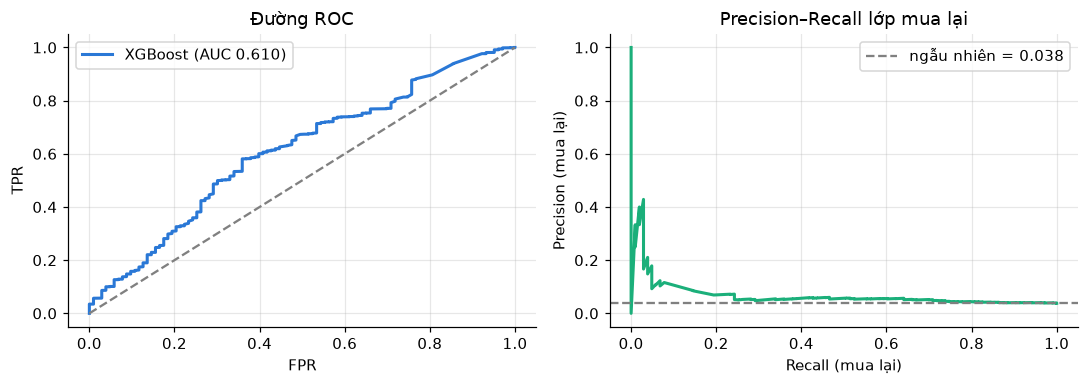

In [9]:
fpr, tpr, _ = roc_curve(y, p)
prec, rec, _ = precision_recall_curve(1 - y, 1 - p)  # lớp thiểu số = mua lại
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(fpr, tpr, color=C[0], lw=2, label=f"{m['best_model']} (AUC {roc_auc_score(y, p):.3f})"); axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR"); axes[0].set_title("Đường ROC"); axes[0].legend()
axes[1].plot(rec, prec, color=C[2], lw=2); axes[1].axhline((1 - y).mean(), ls="--", color="gray", label=f"ngẫu nhiên = {(1 - y).mean():.3f}")
axes[1].set_xlabel("Recall (mua lại)"); axes[1].set_ylabel("Precision (mua lại)"); axes[1].set_title("Precision–Recall lớp mua lại"); axes[1].legend()
plt.tight_layout()

### 3. Chọn ngưỡng quyết định
Xác suất chưa hiệu chỉnh (do trọng số lớp), nên ngưỡng 0,5 không phải là tối ưu cho mọi mục tiêu. Bảng dưới cho thấy đánh đổi khi thay đổi ngưỡng.

In [10]:
rows = []
for t in np.arange(0.3, 0.81, 0.05):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    rows.append({"ngưỡng": round(t, 2), "% dự đoán churn": pred.mean(), "recall churn": tp / (tp + fn),
                 "recall mua lại": tn / (tn + fp), "balanced acc": (tp / (tp + fn) + tn / (tn + fp)) / 2})
pd.DataFrame(rows).set_index("ngưỡng").round(3)

,% dự đoán churn,recall churn,recall mua lại,balanced acc
ngưỡng,,,,
0.30,0.984,0.985,0.049,0.517
0.35,0.848,0.852,0.243,0.547
0.40,0.765,0.769,0.340,0.554
0.45,0.727,0.733,0.427,0.580
0.50,0.670,0.676,0.476,0.576
0.55,0.582,0.589,0.602,0.596
0.60,0.436,0.443,0.718,0.581
0.65,0.263,0.266,0.825,0.546
0.70,0.104,0.105,0.942,0.524


### 4. Giải thích mô hình bằng SHAP

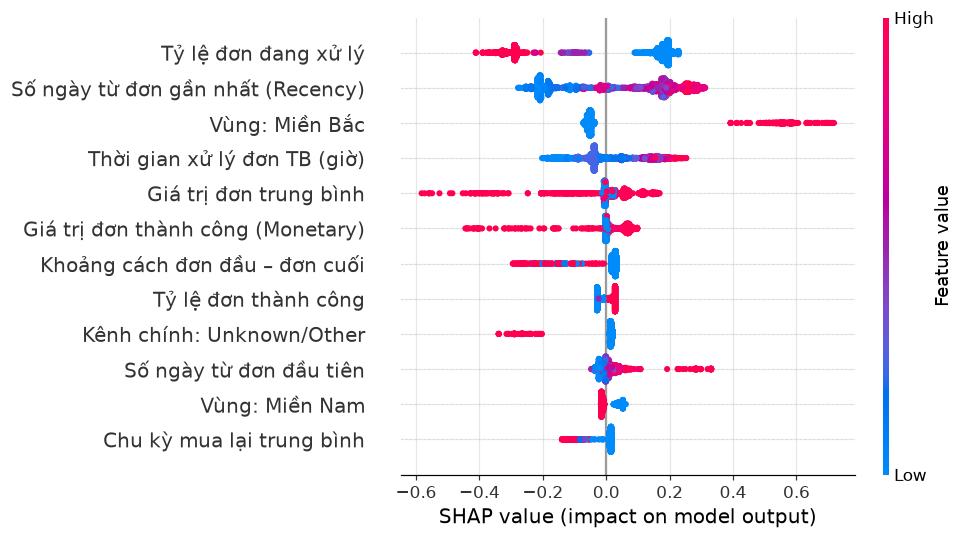

In [11]:
import shap
from omni_dss.ml.explain import make_explainer, shap_matrix
explainer = make_explainer(model)
Xt = data["X_test"][features]
sv = shap_matrix(explainer, Xt)
shap.summary_plot(sv, Xt.rename(columns=fe.FEATURE_LABELS), max_display=12, show=False, plot_size=(9, 5))

Ghi chú: pipeline tính SHAP toàn cục trên **mẫu ngẫu nhiên 800 khách** của tập kiểm tra (`SHAP_SAMPLE` trong `train_advanced.py`), còn notebook tính trên **toàn bộ** tập kiểm tra, nên giá trị mean|SHAP| lệch nhẹ so với `model_metrics.json`; thứ hạng các đặc trưng hàng đầu giữ nguyên.

In [12]:
imp = pd.DataFrame({"đặc trưng": [fe.FEATURE_LABELS.get(f, f) for f in features], "mean|SHAP|": np.abs(sv).mean(0),
                    "tương quan giá trị–SHAP": [np.corrcoef(Xt.iloc[:, j], sv[:, j])[0, 1] if Xt.iloc[:, j].std() > 0 else np.nan for j in range(len(features))]})
imp.sort_values("mean|SHAP|", ascending=False).head(12).round(4)

,đặc trưng,mean|SHAP|,tương quan giá trị–SHAP
14,Tỷ lệ đơn đang xử lý,0.2138,-0.9938
0,Số ngày từ đơn gần nhất (Recency),0.1792,0.8080
30,Vùng: Miền Bắc,0.1209,0.9955
15,Thời gian xử lý đơn TB (giờ),0.0876,0.6774
3,Giá trị đơn trung bình,0.0512,0.0945
2,Giá trị đơn thành công (Monetary),0.0393,0.2902
5,Khoảng cách đơn đầu – đơn cuối,0.0379,-0.6026
11,Tỷ lệ đơn thành công,0.0244,0.9546
28,Kênh chính: Unknown/Other,0.0237,-0.9940
4,Số ngày từ đơn đầu tiên,0.0221,0.6648


In [13]:
# Giải thích cục bộ cho 1 khách hàng có rủi ro cao nhất (mã đã che)
i = int(np.argmax(p))
print("Khách:", mask_customer_id(str(data["X_test"].index[i])), f"| P(churn) = {p[i]:.3f} | thực tế: {'churn' if y[i] else 'mua lại'}")
local = pd.DataFrame({"đặc trưng": [fe.FEATURE_LABELS.get(f, f) for f in features], "giá trị": Xt.iloc[i].values, "SHAP": sv[i]})
local.reindex(local["SHAP"].abs().sort_values(ascending=False).index).head(6).round(4)

Khách: KH_5XEAYIY26N | P(churn) = 0.849 | thực tế: churn


,đặc trưng,giá trị,SHAP
27,Kênh chính: TikTok Shop,1.0000,0.8711
0,Số ngày từ đơn gần nhất (Recency),15.0842,0.2049
14,Tỷ lệ đơn đang xử lý,0.0000,0.1967
15,Thời gian xử lý đơn TB (giờ),210.5856,0.1510
3,Giá trị đơn trung bình,12.8662,0.1467
2,Giá trị đơn thành công (Monetary),12.8662,0.0950
